Suhas Gullapelli - NBA Player Stat Projections

Projects a player's **points, rebounds, and assists** for a game from:
- **Recent form**: averages over the last 5 and 10 games, a weighted longer-term average, and season-to-date averages (basic and advanced stats: usage, assist %, rebound %, true shooting, PIE, possessions)
- **Head-to-head**: the player's past games against this opponent, and how that compares to their usual level
- **Opponent**: the opponent's last 10 games: defensive rating, pace, and points/rebounds/assists allowed
- **Game context**: home or away, rest days, back-to-backs, playoffs, and the player's own team's form

Data comes from `collect_data.py` (NBA stats API, 2015-16 to now). Feature code is in `features.py`; every feature uses only games played before the one being predicted.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from features import load_data, build_features, upcoming_features, FEATURES, TARGETS

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)

In [2]:
players, teams = load_data()
df = build_features(players, teams)
print(df.shape)
df[['PLAYER_NAME', 'GAME_DATE', 'MATCHUP', 'PTS', 'PTS_L5', 'PTS_L10', 'PTS_SEASON', 'PTS_H2H', 'H2H_GP',
    'OPP_DEF_RATING', 'REST_DAYS']].tail()

(303290, 140)


,PLAYER_NAME,GAME_DATE,MATCHUP,PTS,PTS_L5,PTS_L10,PTS_SEASON,PTS_H2H,H2H_GP,OPP_DEF_RATING,REST_DAYS
303285,Myron Gardner,2026-11-02,MIA @ LAL,0,1.20,2.20,1.333333,NaN,0,118.18,3.0
303286,Bronny James,2026-11-02,LAL vs. MIA,2,0.80,1.40,0.666667,2.0,1,118.31,1.0
303287,Lawson Lovering,2026-11-02,LAL vs. MIA,0,7.00,7.00,NaN,NaN,0,118.31,10.0
303288,Cameron Carr,2026-11-02,LAL vs. MIA,0,0.00,0.00,0.000000,NaN,0,118.31,1.0
303289,Ryan Conwell,2026-11-02,MIA @ LAL,5,2.25,2.25,2.250000,NaN,0,118.18,3.0


## Training and test sets

Only games where the player played and had at least 5 earlier games are used. The model trains on 2015-16 through 2024-25 and is tested on the full **2025-26** season, so it is judged on games from a season it never saw.

In [3]:
data = df[(df['MIN'] > 0) & (df['CAREER_GP'] >= 5)].copy()

TEST_SEASON = '2025-26'
train = data[data['SEASON_YEAR'] < TEST_SEASON]
test = data[data['SEASON_YEAR'] == TEST_SEASON]

X_train, X_test = train[FEATURES], test[FEATURES]
print(len(train), 'training games,', len(test), 'test games,', len(FEATURES), 'features')

265273 training games, 28062 test games, 68 features


## Baselines

A projection is only useful if it beats the simple averages people already use, so those are the baselines: the player's last-10-game average and season average.

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error

def scores(y_true, y_pred):
    mask = ~np.isnan(y_pred)
    return {'MAE': mean_absolute_error(y_true[mask], y_pred[mask]),
            'RMSE': np.sqrt(mean_squared_error(y_true[mask], y_pred[mask]))}

results = []
for t in TARGETS:
    y = test[t].values
    # Early in a season there's no season average yet, so fall back to the last-10 average
    season_avg = test[f'{t}_SEASON'].fillna(test[f'{t}_L10']).values
    results.append({'Stat': t, 'Method': 'Last 10 games average', **scores(y, test[f'{t}_L10'].values)})
    results.append({'Stat': t, 'Method': 'Season average', **scores(y, season_avg)})
pd.DataFrame(results).round(3)

,Stat,Method,MAE,RMSE
0,PTS,Last 10 games average,4.678,6.142
1,PTS,Season average,4.708,6.196
2,REB,Last 10 games average,1.938,2.559
3,REB,Season average,1.928,2.554
4,AST,Last 10 games average,1.369,1.870
5,AST,Season average,1.366,1.870


## Training the models

One gradient boosting model per stat. Gradient boosting handles missing values on its own (e.g. no head-to-head history yet), so nothing needs to be filled in.

In [5]:
from sklearn.ensemble import HistGradientBoostingRegressor

models, predictions = {}, {}
for t in TARGETS:
    model = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, max_leaf_nodes=31,
                                          min_samples_leaf=100, l2_regularization=1.0,
                                          early_stopping=True, validation_fraction=0.1, random_state=42)
    model.fit(X_train, train[t])
    models[t] = model
    predictions[t] = model.predict(X_test)
    results.append({'Stat': t, 'Method': 'Gradient Boosting model', **scores(test[t].values, predictions[t])})
    print(t, 'trained with', model.n_iter_, 'trees')

PTS trained with 181 trees


REB trained with 142 trees


AST trained with 207 trees


In [6]:
comparison = pd.DataFrame(results).pivot(index='Method', columns='Stat', values='MAE')[TARGETS]
comparison = comparison.loc[['Season average', 'Last 10 games average', 'Gradient Boosting model']]
print('Mean absolute error on the 2025-26 season (lower is better)')
comparison.round(3)

Mean absolute error on the 2025-26 season (lower is better)


Stat,PTS,REB,AST
Method,,,
Season average,4.708,1.928,1.366
Last 10 games average,4.678,1.938,1.369
Gradient Boosting model,4.539,1.877,1.329


In [7]:
improvement = (1 - comparison.loc['Gradient Boosting model'] / comparison.loc['Last 10 games average']) * 100
print('Model error vs. last-10 average:')
for t in TARGETS:
    print(f'  {t}: {improvement[t]:.1f}% lower')

Model error vs. last-10 average:
  PTS: 3.0% lower
  REB: 3.2% lower
  AST: 2.9% lower


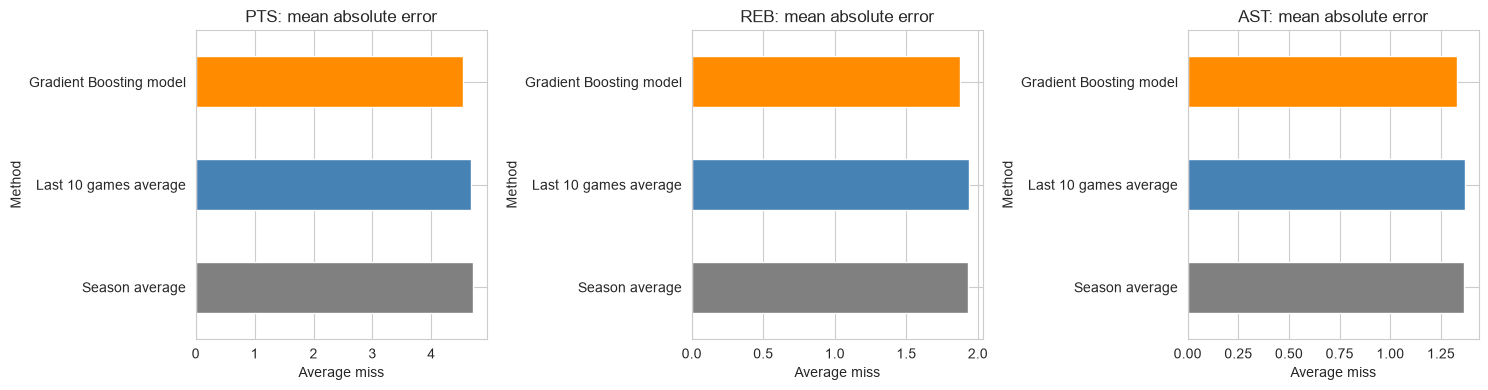

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, t in zip(axes, TARGETS):
    comparison[t].plot(kind='barh', ax=ax, color=['gray', 'steelblue', 'darkorange'])
    ax.set_title(f'{t}: mean absolute error')
    ax.set_xlabel('Average miss')
plt.tight_layout()
plt.show()

## How close are the projections?

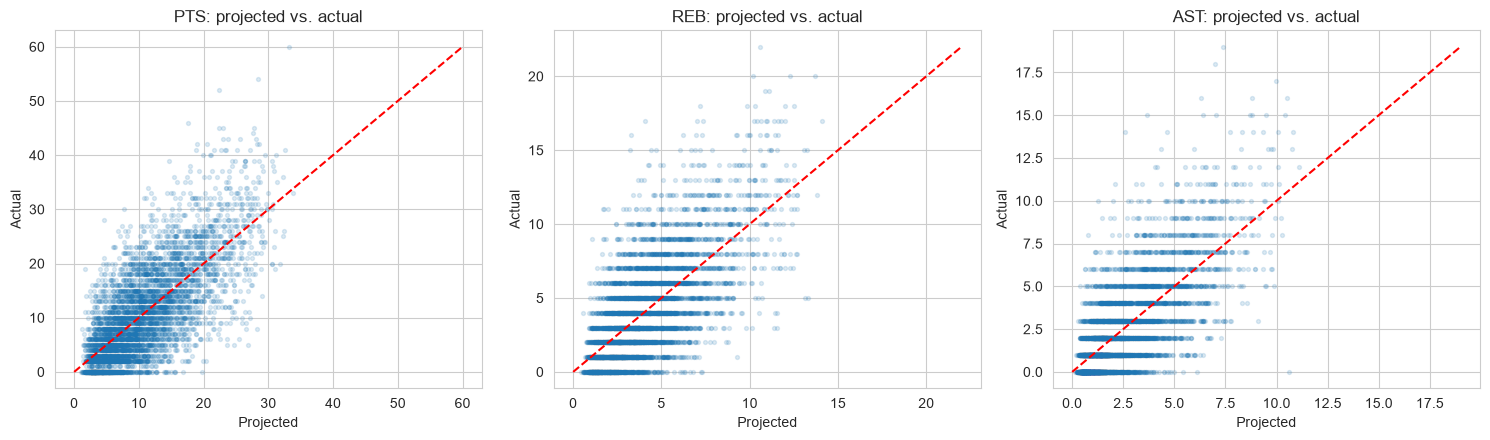

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, t in zip(axes, TARGETS):
    sample = test.assign(pred=predictions[t]).sample(5000, random_state=42)
    ax.scatter(sample['pred'], sample[t], alpha=0.15, s=8)
    top = sample[[t, 'pred']].max().max()
    ax.plot([0, top], [0, top], color='red', linestyle='--')
    ax.set_title(f'{t}: projected vs. actual')
    ax.set_xlabel('Projected')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()

In [10]:
# Average miss for players by how many minutes they usually play
test_eval = test.assign(**{f'{t}_PRED': predictions[t] for t in TARGETS})
test_eval['Minutes'] = pd.cut(test_eval['MIN_L10'], bins=[0, 15, 25, 32, 48],
                              labels=['Under 15', '15-25', '25-32', '32+'])
test_eval.groupby('Minutes').apply(
    lambda g: pd.Series({t: mean_absolute_error(g[t], g[f'{t}_PRED']) for t in TARGETS} | {'Games': len(g)})
).round(2)

,PTS,REB,AST,Games
Minutes,,,,
Under 15,3.28,1.57,0.90,6366.0
15-25,4.31,1.87,1.23,9612.0
25-32,5.11,2.05,1.52,7839.0
32+,5.89,2.05,1.85,4245.0


## Which features matter?

Permutation importance shuffles one feature at a time and measures how much worse the points model gets. This shows whether head-to-head and opponent features add anything beyond recent form.

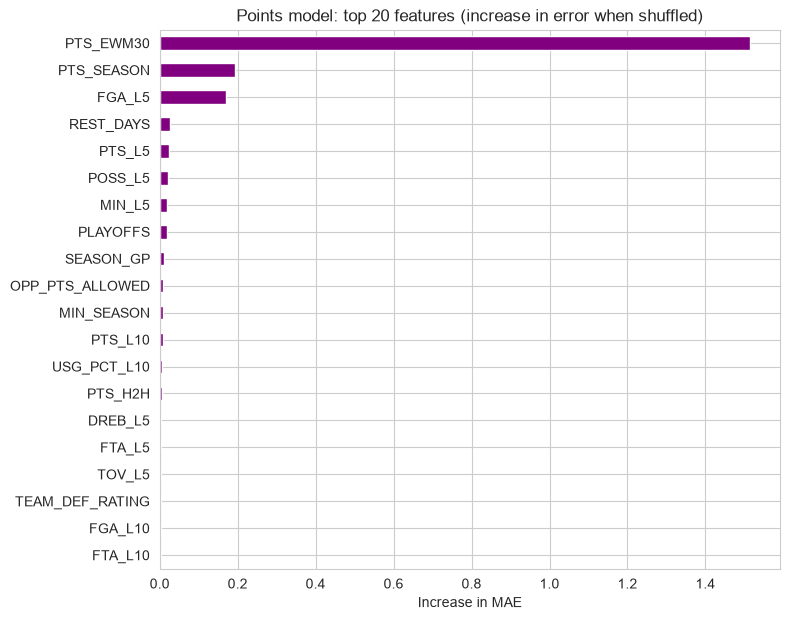

In [11]:
from sklearn.inspection import permutation_importance

sample = test.sample(20000, random_state=42)
result = permutation_importance(models['PTS'], sample[FEATURES], sample['PTS'],
                                scoring='neg_mean_absolute_error', n_repeats=3, random_state=42)
importance = pd.Series(result.importances_mean, index=FEATURES).sort_values()
importance.tail(20).plot(kind='barh', figsize=(8, 7), color='purple',
                         title='Points model: top 20 features (increase in error when shuffled)')
plt.xlabel('Increase in MAE')
plt.show()

In [12]:
def group_of(feature):
    if 'H2H' in feature:
        return 'Head-to-head'
    if feature.startswith('OPP_'):
        return 'Opponent'
    if feature.startswith('TEAM_'):
        return 'Own team'
    if feature in ('REST_DAYS', 'BACK_TO_BACK', 'HOME', 'PLAYOFFS'):
        return 'Game context'
    return 'Player form'

importance.groupby(importance.index.map(group_of)).sum().sort_values(ascending=False).round(4)

Player form     1.9962
Game context    0.0448
Opponent        0.0117
Head-to-head    0.0059
Own team        0.0048
dtype: float64

## Final models

Refit on every season, including 2025-26 and the current season so far, and save them for `project.py`.

In [13]:
import joblib
import sklearn

final_models = {}
for t in TARGETS:
    model = HistGradientBoostingRegressor(max_iter=models[t].n_iter_, learning_rate=0.05, max_leaf_nodes=31,
                                          min_samples_leaf=100, l2_regularization=1.0,
                                          early_stopping=False, random_state=42)
    final_models[t] = model.fit(data[FEATURES], data[t])

joblib.dump({'models': final_models, 'features': FEATURES, 'sklearn_version': sklearn.__version__},
            'projection_models.joblib')

['projection_models.joblib']

## Projecting upcoming games

In [14]:
def project(player, opponent, home, game_date=None):
    row = upcoming_features(players, teams, player, opponent, home, game_date)
    projection = {t: round(float(final_models[t].predict(row[FEATURES])[0]), 1) for t in TARGETS}
    return {'Player': row['PLAYER_NAME'].iloc[0], 'Matchup': row['MATCHUP'].iloc[0], **projection,
            'Last 10 PTS': round(row['PTS_L10'].iloc[0], 1), 'H2H games': int(row['H2H_GP'].iloc[0]),
            'H2H PTS': round(row['PTS_H2H'].iloc[0], 1)}

pd.DataFrame([
    project('Luka Doncic', 'BOS', home=True),
    project('Nikola Jokic', 'MIN', home=False),
    project('Jayson Tatum', 'NYK', home=True),
    project('Victor Wembanyama', 'OKC', home=True),
])

,Player,Matchup,PTS,REB,AST,Last 10 PTS,H2H games,H2H PTS
0,Luka Dončić,LAL vs. BOS,32.9,7.7,8.0,36.3,18,29.7
1,Nikola Jokić,DEN @ MIN,23.1,11.2,9.1,23.8,60,25.3
2,Jayson Tatum,BOS vs. NYK,25.3,7.6,6.9,26.0,35,24.8
3,Victor Wembanyama,SAS vs. OKC,25.4,10.9,3.5,25.5,17,21.2
